In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision, torchvision.transforms as T

In [2]:
# Data
transform = T.Compose([T.ToTensor(), T.Normalize((0.2860,), (0.3530,))])
train_set = torchvision.datasets.FashionMNIST("./data", train=True,  download=True, transform=transform)
test_set  = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=64)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 205kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.74MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.8MB/s]


Device: cuda


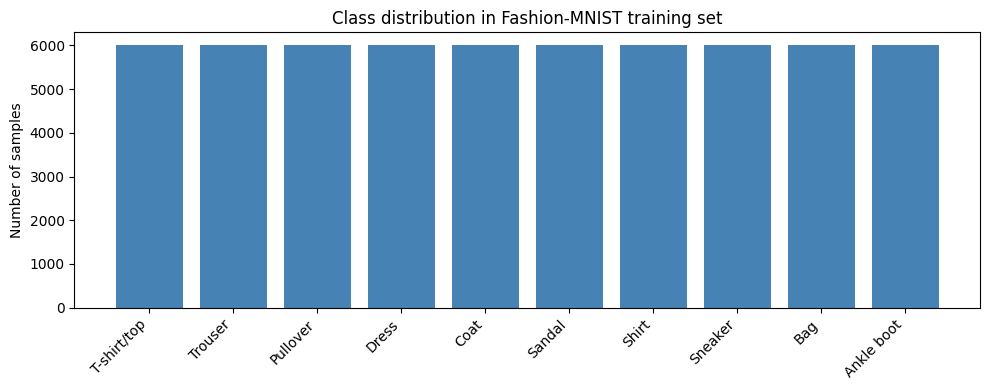

Min class count: 6000
Max class count: 6000


In [6]:
#Class Distribution
import matplotlib.pyplot as plt
from collections import Counter

# Count how many samples per class in the training set
labels_list = [label for _, label in train_set]
counts = Counter(labels_list)

classes = ['T-shirt/top','Trouser','Pullover','Dress','Coat',
           'Sandal','Shirt','Sneaker','Bag','Ankle boot']

plt.figure(figsize=(10, 4))
plt.bar(classes, [counts[i] for i in range(10)], color='steelblue')
plt.title("Class distribution in Fashion-MNIST training set")
plt.ylabel("Number of samples")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("Min class count:", min(counts.values()))
print("Max class count:", max(counts.values()))

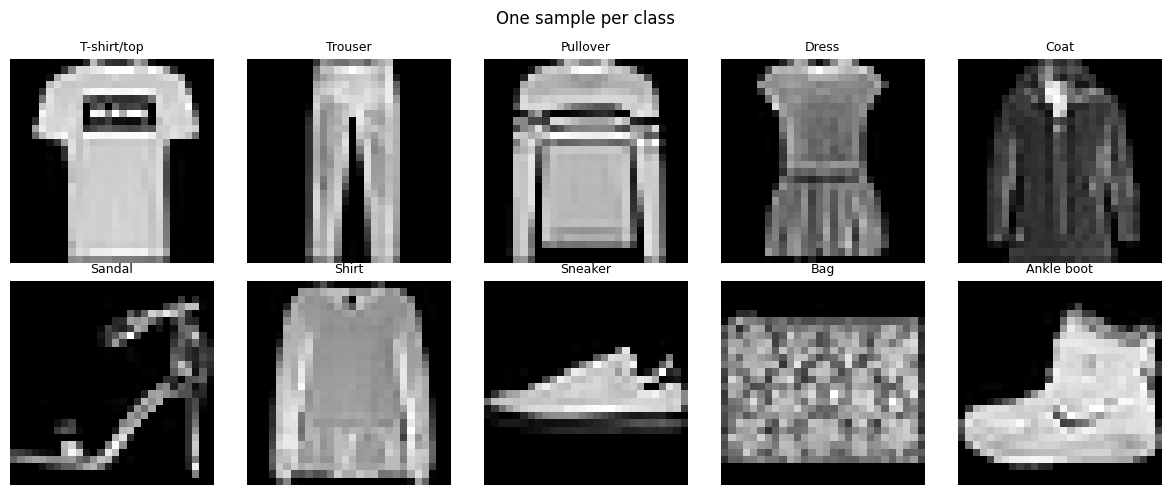

In [7]:
#Sample Images per Class
# Show one example of each class so I know what the model is actually seeing
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
shown = {i: False for i in range(10)}

for img, label in train_set:
    if not shown[label]:
        ax = axes[label // 5, label % 5]
        # img shape is (1, 28, 28); squeeze to (28, 28) for imshow
        ax.imshow(img.squeeze(), cmap='gray')
        ax.set_title(classes[label], fontsize=9)
        ax.axis('off')
        shown[label] = True
    if all(shown.values()):
        break

plt.suptitle("One sample per class")
plt.tight_layout()
plt.show()

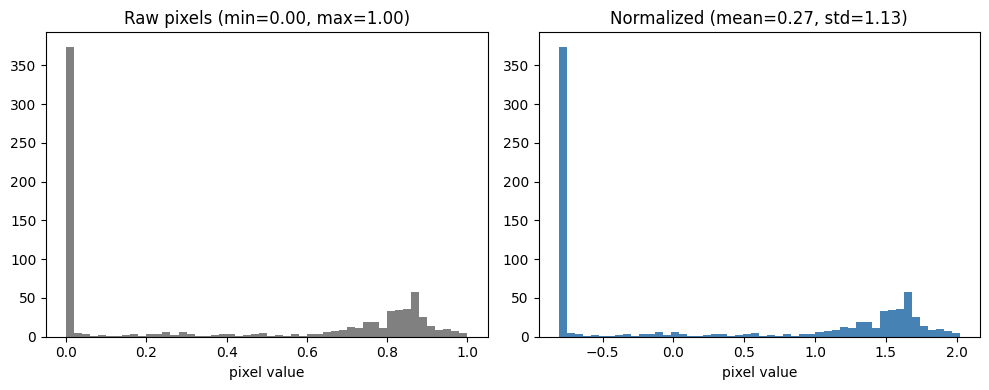

In [9]:
#Pixel Value Distribution (Before vs After Normalization)
# Raw pixel range (before normalization) is 0-1 after ToTensor().
# After Normalize() it's roughly centered around 0.
# Let's inspect both to confirm the transform is working.

raw_transform = T.ToTensor()   # no normalization
raw_set = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=raw_transform)

# Grab one image, raw
raw_img, _ = raw_set[0]
# Grab the same image, normalized (from train_set which has Normalize applied)
norm_img, _ = train_set[0]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(raw_img.numpy().ravel(), bins=50, color='gray')
ax[0].set_title(f"Raw pixels (min={raw_img.min():.2f}, max={raw_img.max():.2f})")
ax[0].set_xlabel("pixel value")

ax[1].hist(norm_img.numpy().ravel(), bins=50, color='steelblue')
ax[1].set_title(f"Normalized (mean={norm_img.mean():.2f}, std={norm_img.std():.2f})")
ax[1].set_xlabel("pixel value")

plt.tight_layout()
plt.show()

In [10]:
 #One Full Batch Grid
 # For Fashion-MNIST the known values are mean=0.2860, std=0.3530.
# But if you ever use a custom dataset, compute them like this:

loader_raw = DataLoader(raw_set, batch_size=1000, shuffle=False)
mean = 0.0; std = 0.0; n = 0

for imgs, _ in loader_raw:
    # imgs shape: (B, 1, 28, 28)
    mean += imgs.mean().item() * imgs.size(0)
    n += imgs.size(0)

mean /= n

# Second pass for std (needs mean first)
for imgs, _ in loader_raw:
    std += ((imgs - mean) ** 2).mean().item() * imgs.size(0)
std = (std / n) ** 0.5

print(f"Computed mean: {mean:.4f}, std: {std:.4f}")
print(f"Official values: mean=0.2860, std=0.3530")

Computed mean: 0.2860, std: 0.3530
Official values: mean=0.2860, std=0.3530


I apply two transforms. ToTensor() converts the PIL image into a float tensor with shape (channels, height, width) and scales pixel values from 0–255 to 0–1. Normalize() then subtracts the dataset mean and divides by the standard deviation, so inputs are roughly centered around zero — this helps training converge faster.

I load Fashion-MNIST, which gives me 60,000 training images and 10,000 test images, all 28×28 grayscale, across 10 clothing classes. I wrap them in DataLoader with batch_size=64 and shuffle=True on the training set so the model doesn't see the same label order every epoch.


In [3]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, stride=1, padding=1)
        self.pool1 = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 32, 3, stride=1, padding=1)
        self.pool2 = nn.MaxPool2d(2, 2)
        self.fc    = nn.Linear(7*7*32, 10)
        self.relu  = nn.ReLU()
        self.flatten = nn.Flatten()

    def forward(self, x, verbose=False):
        x = self.pool1(self.relu(self.conv1(x)))
        if verbose: print("after pool1:", tuple(x.shape))
        x = self.pool2(self.relu(self.conv2(x)))
        if verbose: print("after pool2:", tuple(x.shape))
        x = self.flatten(x)
        if verbose: print("after flatten:", tuple(x.shape))
        return self.fc(x)

model = CNN().to(device)

conv1: 1 input channel → 16 filters, 3×3 kernel, stride 1, padding 1 (keeps 28×28 unchanged)

pool1: 2×2 max pool, stride 2 (halves to 14×14)

conv2: 16 → 32 filters, 3×3 kernel, stride 1, padding 1 (keeps 14×14 unchanged)

pool2: 2×2 max pool, stride 2 (halves to 7×7)

fc: linear layer from 7×7×32 = 1568 → 10 output classes

In [4]:
images, labels = next(iter(train_loader))
print("input:", tuple(images.shape))
_ = model(images.to(device), verbose=True)

input: (64, 1, 28, 28)
after pool1: (64, 16, 14, 14)
after pool2: (64, 32, 7, 7)
after flatten: (64, 1568)


# Cell 3 — Shape Verification

This cell is a **sanity check before training**.

- `next(iter(train_loader))` grabs one batch of 64 images and their labels from the training set.
- `print("input:", tuple(images.shape))` prints the batch shape — expected `(64, 1, 28, 28)` — so I can confirm what's entering the model.
- `model(images.to(device), verbose=True)` pushes that batch through the forward pass and prints the shape after each block: after pool1, after pool2, after flatten.

The underscore `_` just discards the output logits — I don't need predictions here, only the shape printouts.

This lets me compare the **actual** shapes against my **hand-computed** ones:

| Stage | Hand-computed | Expected print |
|-------|---------------|----------------|
| input | (64, 1, 28, 28) | (64, 1, 28, 28) |
| after pool1 | (64, 16, 14, 14) | (64, 16, 14, 14) |
| after pool2 | (64, 32, 7, 7) | (64, 32, 7, 7) |
| after flatten | (64, 1568) | (64, 1568) |

If anything mismatches, the bug is almost always in padding, stride, or pooling kernel size — and I'd fix it before wasting time on training.

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(5):
    model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()                # 1. clear old gradients
        outputs = model(images)              # 2. forward pass
        loss = criterion(outputs, labels)    # 3. compute loss
        loss.backward()                      # 4. backprop
        optimizer.step()                     # 5. update weights

    # Evaluate
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            preds = model(images).argmax(1)
            correct += (preds == labels).sum().item()
            total   += labels.size(0)
    print(f"Epoch {epoch+1}: val acc = {correct/total:.4f}")

Epoch 1: val acc = 0.8688
Epoch 2: val acc = 0.8858
Epoch 3: val acc = 0.8950
Epoch 4: val acc = 0.8966
Epoch 5: val acc = 0.9001


# Cell 4 — Handwritten Training Loop

This cell trains the model for 5 epochs and reports validation accuracy after each one.

**Setup:**
- `CrossEntropyLoss` — the standard loss for multi-class classification. It expects raw logits and integer labels.
- `Adam` optimizer with learning rate `1e-3` — a safe default that adapts per-parameter step sizes.

**Training phase (`model.train()`):**
For every batch of 64 images, I run the five-step pattern:
1. `optimizer.zero_grad()` — clears gradients from the previous batch so they don't accumulate.
2. `model(images)` — forward pass, produces 10 logits per image.
3. `criterion(outputs, labels)` — computes cross-entropy loss.
4. `loss.backward()` — backpropagates to compute gradients for every weight.
5. `optimizer.step()` — updates the weights using those gradients.

**Evaluation phase (`model.eval()` + `torch.no_grad()`):**
- `model.eval()` switches layers like dropout/batchnorm to inference mode.
- `torch.no_grad()` disables gradient tracking — saves memory and speeds things up since we're not updating weights.
- I loop through the test set, take `argmax(1)` to get the predicted class, and count how many match the labels.
- After the loop, I print `correct/total` as validation accuracy.

Expected result: validation accuracy climbs each epoch, typically reaching ~90% by epoch 5 on Fashion-MNIST.

building and training a small convolutional neural network from scratch in PyTorch to classify clothing images. The data I'm using is **Fashion-MNIST** — 60,000 training and 10,000 test grayscale images, each 28×28 pixels, sorted into 10 categories like T-shirts, trousers, sneakers, and bags. I load it with `torchvision`, normalize the pixel values, and feed it in batches of 64 through a `DataLoader`. The model itself is a simple CNN: two conv-pool blocks that extract features, then a flatten and a linear layer that outputs 10 class scores. I train it with a handwritten loop — no `.fit()` — using cross-entropy loss and the Adam optimizer, running the standard five-step cycle (zero gradients, forward, loss, backward, step) for 5 epochs, and checking validation accuracy on the test set after each epoch to see how well it's learning.